In [7]:
from sympy import *
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
import time

# %matplotlib notebook
%matplotlib inline

init_printing(use_latex=True)

Pressure field: -(beta*kappa*(x**2 + y**2)**(3/2)/3 + mu*x**2/2 + mu*y**2/2)/kappa
Flux: s_x = x , s_y = y
Gradient: g_x = -beta*x*sqrt(x**2 + y**2) - mu*x/kappa , g_y = -beta*y*sqrt(x**2 + y**2) - mu*y/kappa
Source term: (12*kappa - zeta*(2*beta*kappa*(x**2 + y**2)**(3/2) + 3*mu*x**2 + 3*mu*y**2))/(6*kappa)
Curl of g: 0


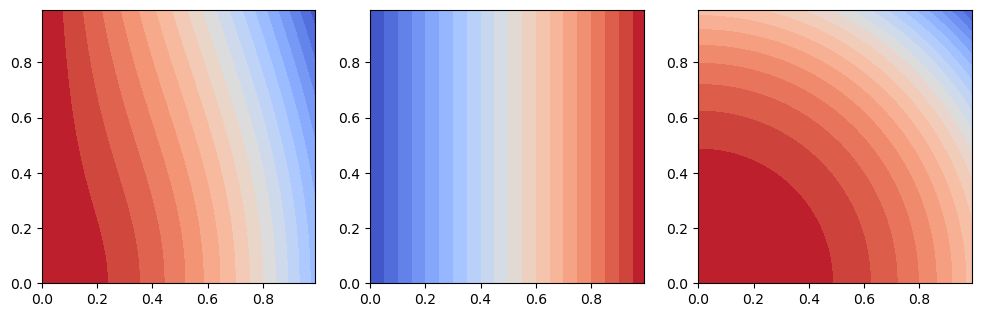

In [ ]:
import numpy as np
import sympy as sym
import matplotlib.pyplot as plt
from sympy import lambdify

# Define symbols
x, y = sym.symbols('x y')
mu, beta, kappa, zeta = sym.symbols('mu beta kappa zeta')

# Flux components
sx, sy = x, y

# Gradient components
gx = -((mu / kappa) * sx + beta * sym.sqrt(sx**2 + sy**2) * sx)
gy = -((mu / kappa) * sy + beta * sym.sqrt(sx**2 + sy**2) * sy)

# Curl (check conservativeness of the gradient vector field)
curl_g = sym.simplify(sym.diff(gy, x) - sym.diff(gx, y))

# Pressure field
px = sym.integrate(gx, x)
p = sym.simplify(px - (mu / (2 * kappa)) * y**2)

# Source term
div_s = sym.diff(sx, x) + sym.diff(sy, y)
source = sym.simplify(div_s + zeta * p)

# Outputs
print("Pressure field:", p)
print("Flux: s_x =", sx, ", s_y =", sy)
print("Gradient: g_x =", gx, ", g_y =", gy)
print("Source term:", source)
print("Curl of g:", curl_g)

# Lambdify the expressions for numerical evaluation
pressure = lambdify([x, y], p.subs({mu: 1.0, kappa: 1.0, beta: 10.0}))
gradx = lambdify([x, y], gx.subs({mu: 1.0, kappa: 1.0, beta: 10.0}))
fluxx = lambdify([x, y], sx.subs({mu: 1.0, kappa: 1.0, beta: 10.0}))

# Domain definition
L, H = 1.0, 1.0 
xa = np.arange(0, L, L / 100)
ya = np.arange(0, H, H / 100)
X, Y = np.meshgrid(xa, ya)
P = pressure(X, Y)
Gx = gradx(X, Y)
Sx = fluxx(X, Y)

# Plot results
fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
fig.set_figwidth(12)
fig.set_figheight(12)
ax1.contourf(X, Y, Gx, 20, cmap='coolwarm')
ax2.contourf(X, Y, Sx, 20, cmap='coolwarm')
ax3.contourf(X, Y, P, 20, cmap='coolwarm')
ax1.set_aspect('equal', 'box')
ax2.set_aspect('equal', 'box')
ax3.set_aspect('equal', 'box')
plt.show()


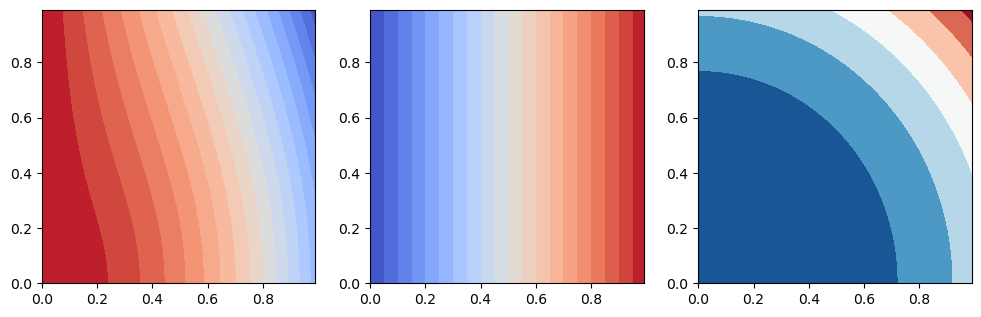

In [10]:
p = px -mu*y**2/(2*kappa)
pressure = lambdify([x,y],p.subs({mu:1.0,kappa:1.0,beta:10.0}))
gradx = lambdify([x,y],gx.subs({mu:1.0,kappa:1.0,beta:10.0}))
fluxx = lambdify([x,y],sx.subs({mu:1.0,kappa:1.0,beta:10.0}))
xa = np.arange(0,L,L/100)
ya = np.arange(0,H,H/100)
X,Y=np.meshgrid(xa,ya)
P = pressure(X,Y)
Gx = gradx(X,Y)
Sx = fluxx(X,Y)

fig, (ax1, ax2, ax3) = plt.subplots(1,3)
fig.set_figwidth(12)
fig.set_figheight(12)

#help(ax1.contourf)
ax1.contourf(X, Y, Gx, 20, cmap='coolwarm')
ax2.contourf(X, Y, Sx, 20, cmap='coolwarm')
ax3.contourf(X, Y, P, 20, cmap='coolwarm')
ax1.set_aspect('equal', 'box')
ax2.set_aspect('equal', 'box')
ax3.set_aspect('equal', 'box')

cp = plt.contourf(X, Y, P, cmap='RdBu')

plt.show()